# 07 - Calibration and class-prior correction (no retraining)
Two cheap, well-known fixes that use only the predictions already saved by notebook 03. Everything is fitted on the **validation** scans and then applied once to the **test** scans.

**1. Temperature scaling.** After training for many epochs a network is usually over-confident (validation loss rises while accuracy stays flat). One number `T` rescales the confidences so they match how often the model is actually right. Accuracy does not change; calibration (ECE) and the uncertainty score usually improve.

**2. Class-prior correction.** Training used *class-balanced* sampling (every class equally often), but in the real data CNV is far more common than DRUSEN. A model trained that way over-predicts the rare classes (this is why DME and DRUSEN have lower precision than recall). Multiplying the probabilities by `prior^alpha` corrects for it; `alpha` is chosen on validation.

Both are reported with 95% intervals and paired tests against the original predictions, so you can see whether they genuinely help. If they do not, the notebook says so.

Needs only numpy and matplotlib. Takes a minute.

## 1. Settings and load

In [1]:
import json, math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# ---------------- settings ----------------
RUN = "cnn_softmax_s42"                                              # run to improve (folder in outputs/runs)
RUNS_DIR = Path("outputs") / "runs"
OUT_ROOT = Path("C:/Users/User/Desktop/retinaldataset/OCT_clean")    # for the class frequencies (pipeline.json)
OUT_DIR = Path("outputs") / "calibration" / RUN
N_BOOT = 2000
ALPHAS = [0.0, 0.25, 0.5, 0.75, 1.0]                                 # strength of the prior correction to try
# -------------------------------------------

RUN_DIR = RUNS_DIR / RUN
for f in ("val_outputs.npz", "test_outputs.npz", "metrics.json"):
    if not (RUN_DIR / f).exists():
        raise FileNotFoundError(f"{RUN_DIR / f} not found - finish notebook 03 for this run first.")
OUT_DIR.mkdir(parents=True, exist_ok=True)

val, test = dict(np.load(RUN_DIR / "val_outputs.npz")), dict(np.load(RUN_DIR / "test_outputs.npz", allow_pickle=False))
M = json.load(open(RUN_DIR / "metrics.json"))
CLASSES = list(M["test"]["per_class"])
K = len(CLASSES)
HEAD = M["cfg"].get("head", "softmax")
PIPE = json.load(open(OUT_ROOT / "pipeline.json")) if (OUT_ROOT / "pipeline.json").exists() else {}

counts = PIPE.get("train_class_counts")
if counts and all(c in counts for c in CLASSES):
    PRIOR = np.array([counts[c] for c in CLASSES], dtype=float)
    prior_src = "training-split class counts (pipeline.json)"
else:
    PRIOR = np.bincount(val["y"], minlength=K).astype(float)
    prior_src = "validation class frequencies (pipeline.json not found)"
PRIOR /= PRIOR.sum()
SAMPLER = PIPE.get("sampler", "balanced")

print(f"Run {RUN} | head: {HEAD} | classes: {CLASSES}")
print(f"validation scans {len(val['y']):,} | test scans {len(test['y']):,}")
print("Natural class prior (" + prior_src + "):", {c: round(float(p), 3) for c, p in zip(CLASSES, PRIOR)})
print("Training sampler:", SAMPLER, "-> " + ("the network saw every class equally often, so the prior correction is expected to matter."
      if SAMPLER == "balanced" else "the network saw the natural class mix, so little prior correction is expected."))
if HEAD == "evidential":
    print("NOTE: this run is evidential; its saved probabilities are alpha/S, so temperature scaling is only approximate.")

Run cnn_softmax_s42 | head: softmax | classes: ['CNV', 'DME', 'DRUSEN', 'NORMAL']
validation scans 7,789 | test scans 7,734
Natural class prior (training-split class counts (pipeline.json)): {'CNV': 0.409, 'DME': 0.145, 'DRUSEN': 0.101, 'NORMAL': 0.345}
Training sampler: balanced -> the network saw every class equally often, so the prior correction is expected to matter.


## 2. Helpers

In [2]:
def softmax(z):
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def confusion(y, p, k):
    return np.bincount(y * k + p, minlength=k * k).reshape(k, k)

def prf(cm):
    tp = np.diag(cm).astype(float)
    prec = tp / np.maximum(cm.sum(0), 1)
    rec = tp / np.maximum(cm.sum(1), 1)
    return prec, rec, 2 * prec * rec / np.maximum(prec + rec, 1e-12)

def nll(p, y):
    return float(-np.log(np.clip(p[np.arange(len(y)), y], 1e-12, 1.0)).mean())

def ece_score(probs, y, bins=15):
    conf, pred = probs.max(1), probs.argmax(1)
    ok = (pred == y).astype(float)
    edges = np.linspace(0, 1, bins + 1)
    e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(ok[m].mean() - conf[m].mean())
    return float(e)

def auroc(pos, neg):
    v = np.concatenate([pos, neg])
    _, inv, cnt = np.unique(v, return_inverse=True, return_counts=True)
    r = (np.cumsum(cnt) - (cnt - 1) / 2.0)[inv]
    n1, n0 = len(pos), len(neg)
    return float((r[:n1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))

def acc_at_coverage(y, pred, unc, cov):
    keep = np.argsort(unc, kind="stable")[:max(1, int(round(cov * len(y))))]
    return float((y[keep] == pred[keep]).mean())

def apply_cal(probs, T, weights):
    # softmax(log p / T) re-weighted by class weights; for a softmax model log p equals the logits up to a constant
    z = np.log(np.clip(probs, 1e-12, 1.0)) / T + np.log(weights)
    return softmax(z)

def evaluate(y, probs):
    pred = probs.argmax(1)
    unc = 1.0 - probs.max(1)
    cm = confusion(y, pred, K)
    prec, rec, f1 = prf(cm)
    cor = pred == y
    return dict(pred=pred, unc=unc, probs=probs, cm=cm, acc=float(cor.mean()), macro_f1=float(f1.mean()), ece=ece_score(probs, y), nll=nll(probs, y),
                auroc=auroc(unc[~cor], unc[cor]) if (~cor).any() and cor.any() else None, errors=int((~cor).sum()),
                acc90=acc_at_coverage(y, pred, unc, 0.9), acc80=acc_at_coverage(y, pred, unc, 0.8),
                precision=prec, recall=rec, f1=f1)

def mcnemar_exact(a_ok, b_ok):
    b, c = int((a_ok & ~b_ok).sum()), int((~a_ok & b_ok).sum())
    n = b + c
    if n == 0:
        return 1.0, b, c
    return min(1.0, 2 * sum(math.comb(n, i) for i in range(min(b, c) + 1)) / 2 ** n), b, c

def boot_ci(y, ev, n_boot, seed=0):
    rg = np.random.default_rng(seed)
    n = len(y)
    accs, f1s = [], []
    for _ in range(n_boot):
        idx = rg.integers(0, n, n)
        accs.append((ev["pred"][idx] == y[idx]).mean())
        f1s.append(prf(confusion(y[idx], ev["pred"][idx], K))[2].mean())
    return [float(v) for v in np.percentile(accs, [2.5, 97.5])], [float(v) for v in np.percentile(f1s, [2.5, 97.5])]

def paired_boot(y, a, b, n_boot, seed=0):
    # differences a - b over resampled test scans
    rg = np.random.default_rng(seed)
    n = len(y)
    d = {"acc": [], "f1": [], "ece": [], "auroc": []}
    for _ in range(n_boot):
        idx = rg.integers(0, n, n)
        yy = y[idx]
        pa, pb = a["pred"][idx], b["pred"][idx]
        d["acc"].append((pa == yy).mean() - (pb == yy).mean())
        d["f1"].append(prf(confusion(yy, pa, K))[2].mean() - prf(confusion(yy, pb, K))[2].mean())
        d["ece"].append(ece_score(a["probs"][idx], yy) - ece_score(b["probs"][idx], yy))
        wa, wb = pa != yy, pb != yy
        if wa.any() and (~wa).any() and wb.any() and (~wb).any():
            d["auroc"].append(auroc(a["unc"][idx][wa], a["unc"][idx][~wa]) - auroc(b["unc"][idx][wb], b["unc"][idx][~wb]))
    return {k: tuple(float(x) for x in np.percentile(v, [2.5, 97.5])) for k, v in d.items() if len(v) > 50}

def verdict(ci, lower_is_better=False):
    if ci is None:
        return "n/a"
    lo, hi = ci
    if lower_is_better:
        lo, hi = -hi, -lo
    return "better" if lo > 0 else ("worse" if hi < 0 else "no clear difference")

## 3. Where the model stands (original predictions)

In [3]:
v0 = evaluate(val["y"], val["probs"])
t0 = evaluate(test["y"], test["probs"])
fmt = lambda v, nd=4: "n/a" if v is None else format(v, "." + str(nd) + "f")
print("             acc      macro-F1   ECE      NLL      AUROC(err)")
for name, e in (("validation", v0), ("test      ", t0)):
    print(f"{name}  {e['acc'] * 100:6.2f}%  {e['macro_f1']:.4f}   {e['ece']:.4f}   {e['nll']:.4f}   {fmt(e['auroc'], 3)}")
print("\nTest precision / recall per class (original):")
for i, c in enumerate(CLASSES):
    print(f"  {c:7s} precision {t0['precision'][i]:.3f}  recall {t0['recall'][i]:.3f}")
over = [CLASSES[i] for i in range(K) if t0["precision"][i] < t0["recall"][i] - 0.03]
if over:
    print("\nPrecision is clearly below recall for:", ", ".join(over), "- a sign that these classes are over-predicted (prior shift from balanced sampling).")

             acc      macro-F1   ECE      NLL      AUROC(err)
validation   96.38%  0.9508   0.0298   0.1892   0.887
test         93.69%  0.9207   0.0511   0.3309   0.831

Test precision / recall per class (original):
  CNV     precision 0.974  recall 0.906
  DME     precision 0.839  recall 0.947
  DRUSEN  precision 0.838  recall 0.919
  NORMAL  precision 0.978  recall 0.978

Precision is clearly below recall for: DME, DRUSEN - a sign that these classes are over-predicted (prior shift from balanced sampling).


## 4. Temperature scaling
`T` is chosen on the validation scans to minimise the negative log-likelihood. `T > 1` means the model was over-confident; `T < 1` under-confident.

In [4]:
T_GRID = np.exp(np.linspace(np.log(0.3), np.log(6.0), 300))
ones = np.ones(K)
nlls = [nll(apply_cal(val["probs"], T, ones), val["y"]) for T in T_GRID]
T_BEST = float(T_GRID[int(np.argmin(nlls))])
vT = evaluate(val["y"], apply_cal(val["probs"], T_BEST, ones))
print(f"Best temperature T = {T_BEST:.3f}  ({'over-confident model' if T_BEST > 1.05 else 'under-confident model' if T_BEST < 0.95 else 'already close to calibrated'})")
print(f"validation NLL {v0['nll']:.4f} -> {vT['nll']:.4f} | validation ECE {v0['ece']:.4f} -> {vT['ece']:.4f} | accuracy unchanged: "
      f"{v0['acc'] * 100:.2f}% -> {vT['acc'] * 100:.2f}%")

Best temperature T = 1.993  (over-confident model)
validation NLL 0.1892 -> 0.1244 | validation ECE 0.0298 -> 0.0069 | accuracy unchanged: 96.38% -> 96.38%


## 5. Class-prior correction
Weights `prior^alpha` are applied on top of the temperature-scaled probabilities. `alpha = 0` means no correction, `alpha = 1` the full correction. The value with the best **validation macro-F1** is kept (ties go to the smaller alpha).

In [5]:
rows = []
for a in ALPHAS:
    e = evaluate(val["y"], apply_cal(val["probs"], T_BEST, PRIOR ** a))
    rows.append((a, e["acc"], e["macro_f1"], e["ece"]))
print("alpha   val acc   val macro-F1   val ECE")
for a, acc, f1, ece in rows:
    print(f"{a:5.2f}   {acc * 100:6.2f}%   {f1:.4f}        {ece:.4f}")
best_f1 = max(r[2] for r in rows)
ALPHA_BEST = min(r[0] for r in rows if r[2] >= best_f1 - 1e-12)
print(f"\nSelected alpha = {ALPHA_BEST} (validation macro-F1 {best_f1:.4f}).")
if ALPHA_BEST == 0.0:
    print("No prior correction helped on validation, so only temperature scaling is applied.")

alpha   val acc   val macro-F1   val ECE
 0.00    96.38%   0.9508        0.0069
 0.25    96.41%   0.9511        0.0065
 0.50    96.41%   0.9509        0.0049
 0.75    96.37%   0.9501        0.0037
 1.00    96.35%   0.9496        0.0065

Selected alpha = 0.25 (validation macro-F1 0.9511).


## 6. Test-set results (applied once)
Three versions on the same test scans: **original**, **+ temperature**, **+ temperature + prior**. Differences to the original come with 95% bootstrap intervals and a McNemar test on the scans where the predictions differ.

In [6]:
W_BEST = PRIOR ** ALPHA_BEST
VERS = {"original": t0,
        "+ temperature": evaluate(test["y"], apply_cal(test["probs"], T_BEST, ones)),
        "+ temperature + prior": evaluate(test["y"], apply_cal(test["probs"], T_BEST, W_BEST))}
y = test["y"]
CI = {}
print(f"{'version':24s}{'accuracy (95% CI)':26s}{'macro-F1 (95% CI)':26s}{'ECE':>8s}{'NLL':>8s}{'AUROC':>8s}{'acc@90':>8s}{'errors':>8s}")
for name, e in VERS.items():
    a_ci, f_ci = boot_ci(y, e, N_BOOT)
    CI[name] = dict(acc=a_ci, f1=f_ci)
    print(f"{name:24s}{e['acc'] * 100:6.2f}% [{a_ci[0] * 100:.2f}, {a_ci[1] * 100:.2f}]".ljust(50) +
          f"{e['macro_f1']:.4f} [{f_ci[0]:.4f}, {f_ci[1]:.4f}]".ljust(26) + f"{e['ece']:8.4f}{e['nll']:8.4f}{fmt(e['auroc'], 3):>8s}{e['acc90'] * 100:7.2f}%{e['errors']:8d}")

PAIRED = {}
print("\nDifference to the original predictions (version minus original):")
for name in ("+ temperature", "+ temperature + prior"):
    e = VERS[name]
    p, only_new, only_old = mcnemar_exact(e["pred"] == y, t0["pred"] == y)
    d = paired_boot(y, e, t0, N_BOOT)
    PAIRED[name] = dict(mcnemar_p=p, only_new_right=only_new, only_old_right=only_old, **d)
    print(f"  {name}")
    print(f"     accuracy : {(e['acc'] - t0['acc']) * 100:+.2f} pp  (McNemar p = {p:.3g}; only new right: {only_new}, only old right: {only_old})")
    if "f1" in d:
        print(f"     macro-F1 : [{d['f1'][0]:+.4f}, {d['f1'][1]:+.4f}] -> {verdict(d['f1'])}")
    if "ece" in d:
        print(f"     ECE      : [{d['ece'][0]:+.4f}, {d['ece'][1]:+.4f}] -> {verdict(d['ece'], lower_is_better=True)}")
    if "auroc" in d:
        print(f"     AUROC    : [{d['auroc'][0]:+.3f}, {d['auroc'][1]:+.3f}] -> {verdict(d['auroc'])}")

fin = VERS["+ temperature + prior"]
print("\nPer class (original -> final):")
print("  " + "class".ljust(8) + "precision".rjust(18) + "recall".rjust(18) + "F1".rjust(18))
for i, c in enumerate(CLASSES):
    print("  " + c.ljust(8) + f"{t0['precision'][i]:.3f} -> {fin['precision'][i]:.3f}".rjust(18) +
          f"{t0['recall'][i]:.3f} -> {fin['recall'][i]:.3f}".rjust(18) + f"{t0['f1'][i]:.3f} -> {fin['f1'][i]:.3f}".rjust(18))

version                 accuracy (95% CI)         macro-F1 (95% CI)              ECE     NLL   AUROC  acc@90  errors
original                 93.69% [93.13, 94.19]    0.9207 [0.9137, 0.9273]     0.0511  0.3309   0.831  96.98%     488
+ temperature            93.69% [93.13, 94.19]    0.9207 [0.9137, 0.9273]     0.0231  0.2045   0.825  96.95%     488
+ temperature + prior    93.75% [93.20, 94.25]    0.9212 [0.9142, 0.9274]     0.0228  0.1965   0.845  97.04%     483

Difference to the original predictions (version minus original):
  + temperature
     accuracy : +0.00 pp  (McNemar p = 1; only new right: 0, only old right: 0)
     macro-F1 : [+0.0000, +0.0000] -> no clear difference
     ECE      : [-0.0291, -0.0266] -> better
     AUROC    : [-0.008, -0.005] -> worse
  + temperature + prior
     accuracy : +0.06 pp  (McNemar p = 0.551; only new right: 25, only old right: 20)
     macro-F1 : [-0.0018, +0.0028] -> no clear difference
     ECE      : [-0.0300, -0.0268] -> better
     AUROC  

## 7. Plots

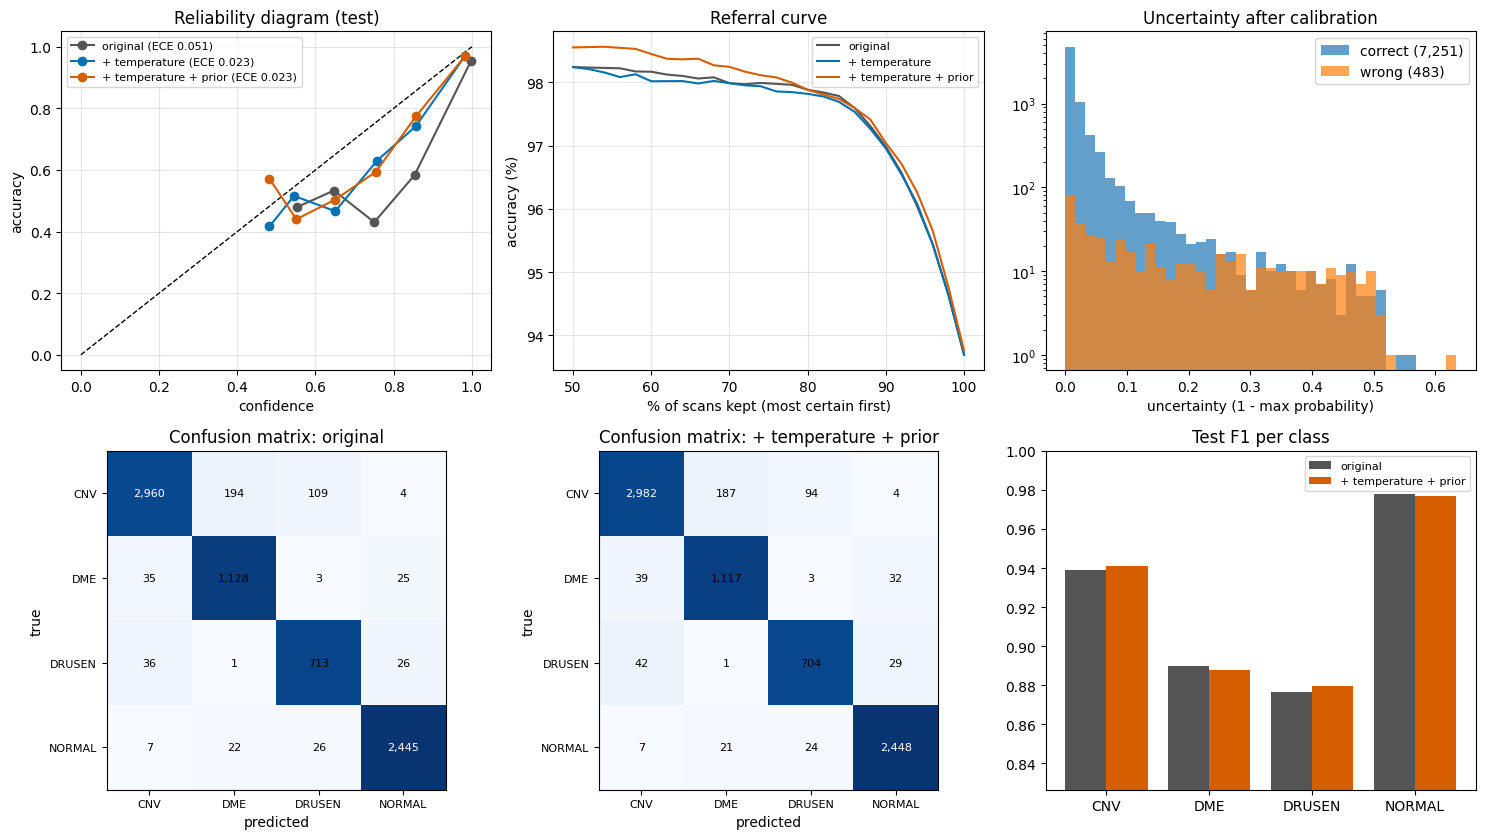

In [7]:
fig, axs = plt.subplots(2, 3, figsize=(15, 8.5))
colors = {"original": "#555555", "+ temperature": "#0072B2", "+ temperature + prior": "#D55E00"}

axs[0, 0].plot([0, 1], [0, 1], "k--", lw=1)
for name, e in VERS.items():
    conf, cor = e["probs"].max(1), (e["pred"] == y).astype(float)
    edges = np.linspace(0, 1, 11)
    xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 10:
            xs.append(conf[m].mean()); ys.append(cor[m].mean())
    axs[0, 0].plot(xs, ys, "o-", color=colors[name], label=f"{name} (ECE {e['ece']:.3f})")
axs[0, 0].set_xlabel("confidence"); axs[0, 0].set_ylabel("accuracy"); axs[0, 0].set_title("Reliability diagram (test)"); axs[0, 0].legend(fontsize=8); axs[0, 0].grid(alpha=0.3)

cov = np.linspace(0.5, 1.0, 26)
for name, e in VERS.items():
    axs[0, 1].plot(cov * 100, [acc_at_coverage(y, e["pred"], e["unc"], c) * 100 for c in cov], color=colors[name], label=name)
axs[0, 1].set_xlabel("% of scans kept (most certain first)"); axs[0, 1].set_ylabel("accuracy (%)"); axs[0, 1].set_title("Referral curve"); axs[0, 1].legend(fontsize=8); axs[0, 1].grid(alpha=0.3)

okm = fin["pred"] == y
bins = np.linspace(0, max(fin["unc"].max(), 1e-6), 40)
axs[0, 2].hist(fin["unc"][okm], bins=bins, alpha=0.7, label=f"correct ({okm.sum():,})")
if (~okm).any():
    axs[0, 2].hist(fin["unc"][~okm], bins=bins, alpha=0.7, label=f"wrong ({(~okm).sum():,})")
axs[0, 2].set_yscale("log"); axs[0, 2].set_xlabel("uncertainty (1 - max probability)"); axs[0, 2].set_title("Uncertainty after calibration"); axs[0, 2].legend()

for ax, (name, e) in zip(axs[1, :2], (("original", t0), ("+ temperature + prior", fin))):
    cm = e["cm"]
    ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=8, color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(K)); ax.set_xticklabels(CLASSES, fontsize=8); ax.set_yticks(range(K)); ax.set_yticklabels(CLASSES, fontsize=8)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"Confusion matrix: {name}")

x = np.arange(K)
axs[1, 2].bar(x - 0.2, t0["f1"], 0.4, label="original", color="#555555")
axs[1, 2].bar(x + 0.2, fin["f1"], 0.4, label="+ temperature + prior", color="#D55E00")
axs[1, 2].set_xticks(x); axs[1, 2].set_xticklabels(CLASSES); axs[1, 2].set_ylim(max(0, min(t0["f1"].min(), fin["f1"].min()) - 0.05), 1.0)
axs[1, 2].set_title("Test F1 per class"); axs[1, 2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "calibration_plots.png", dpi=150); plt.show()

## 8. Save and summary

In [ ]:
def pack(e, name):
    return dict(acc=e["acc"], macro_f1=e["macro_f1"], ece=e["ece"], nll=e["nll"], auroc=e["auroc"], acc_at_90=e["acc90"], acc_at_80=e["acc80"],
                errors=e["errors"], acc_ci95=CI[name]["acc"], f1_ci95=CI[name]["f1"], confusion_matrix=e["cm"].tolist(),
                per_class={c: dict(precision=float(e["precision"][i]), recall=float(e["recall"][i]), f1=float(e["f1"][i])) for i, c in enumerate(CLASSES)})

json.dump(dict(run=RUN, temperature=T_BEST, alpha=ALPHA_BEST, prior=[float(p) for p in PRIOR], classes=CLASSES,
               prior_source=prior_src, alpha_search=[dict(alpha=a, val_acc=acc, val_macro_f1=f1, val_ece=ece) for a, acc, f1, ece in rows]),
          open(OUT_DIR / "calibration.json", "w"), indent=2)
json.dump(dict(run=RUN, versions={n: pack(e, n) for n, e in VERS.items()}, paired_vs_original=PAIRED),
          open(OUT_DIR / "metrics_calibrated.json", "w"), indent=2)

extra = {"paths": test["paths"]} if "paths" in test else {}
np.savez(OUT_DIR / "test_outputs_calibrated.npz", y=y, pred=fin["pred"], unc=fin["unc"], probs=fin["probs"], **extra)
fv = evaluate(val["y"], apply_cal(val["probs"], T_BEST, W_BEST))
np.savez(OUT_DIR / "val_outputs_calibrated.npz", y=val["y"], pred=fv["pred"], unc=fv["unc"], probs=fv["probs"])

f = VERS["+ temperature + prior"]
print(f"Run {RUN}: temperature T = {T_BEST:.3f}, prior strength alpha = {ALPHA_BEST}")
print(f"  accuracy {t0['acc'] * 100:.2f}% -> {f['acc'] * 100:.2f}%  |  macro-F1 {t0['macro_f1']:.4f} -> {f['macro_f1']:.4f}  |  "
      f"ECE {t0['ece']:.4f} -> {f['ece']:.4f}  |  AUROC(err) {fmt(t0['auroc'], 3)} -> {fmt(f['auroc'], 3)}")
print("  (only call a change an improvement where the interval above excludes zero)")
print("\nSaved in", OUT_DIR.resolve())
print("  calibration.json (T, alpha, prior), metrics_calibrated.json, test_outputs_calibrated.npz, val_outputs_calibrated.npz, calibration_plots.png")

## How to explain this in the report / viva
- *Why temperature scaling?* The network keeps getting more confident while training even when it is not getting more accurate, so its probabilities over-state how often it is right. A single scalar fitted on validation data rescales them; the predicted class never changes.
- *Why a prior correction?* Balanced sampling made the network behave as if every class were equally common, but CNV is roughly four times as common as DRUSEN in the data. Re-weighting by the real class frequencies moves the decision boundaries back. It is chosen on validation, not on test.
- *What these are not:* they do not make the model more accurate at recognising anatomy; they fix confidence and class balance. They also do **not** teach it to say "I have never seen this disease" - that needs open-set methods or an explicit "other" class.
- Always say which numbers were fitted on validation and which were measured once on test.